# Customer Segmentation for an Online Retailer using Clustering

**MIS 451 - Machine Learning for Business** · Group Project: *Clustering - Business Pattern Discovery and Segmentation*

| Part | Member | Sections |
|---|---|---|
| A | Dương| 1-4: Business context, data collection, EDA |
| B | Như | 5-6: Data cleaning, feature engineering |
| C | Ngọc | 7-8: Models and evaluation |
| D | Bảo | 9-11: Cluster profiling, tool comparison, limitations |

**Dataset:** Online Retail II - UCI Machine Learning Repository

## Table of Contents
**Part A - Dương**
1. Business Context & Objectives
2. Data Collection
3. Setup & Load Data
4. Exploratory Data Analysis (EDA)

**Part B - Như**

5. Data Cleaning
6. Feature Engineering & Transformation

**Part C - Ngọc**

7. Model Development
8. Model Evaluation & Comparison

**Part D - Bảo**

9. Cluster Profiling & Business Recommendations
10. Tool Comparison: Python vs Orange vs Julius AI
11. Limitations & Future Work


---
# Part A

## 1. Business Context & Objectives

**Context.** The company is a UK-based online retailer selling unique all-occasion gifts. Many of its customers are wholesalers. The business has over one million transactions but treats all customers the same way in its marketing.

**Problem.** Without knowing which customers are valuable, loyal, new or about to leave, marketing budget is spent evenly and high-value customers may churn unnoticed.

**Objective.** Use unsupervised learning (clustering) to group customers by their purchasing behaviour, then turn each segment into a concrete marketing action.

**Key questions**
- What distinct customer segments exist?
- Which segments generate most of the revenue?
- Which customers are at risk of leaving, and how can we win them back?

## 2. Data Collection

- **Source:** UCI Machine Learning Repository - Online Retail II (https://archive.ics.uci.edu/dataset/502/online+retail+ii)
- **Period:** 01/12/2009 - 09/12/2011
- **Size:** 1,067,371 transactions, 8 columns
- **Original format:** Excel file with 2 sheets (2009-2010 and 2010-2011).

| Column | Description |
|---|---|
| Invoice | Invoice number. Starts with "C" if the order was cancelled |
| StockCode | Product code |
| Description | Product name |
| Quantity | Quantity of the product in the invoice |
| InvoiceDate | Date and time of the invoice |
| Price | Unit price (£) |
| Customer ID | Unique customer number |
| Country | Customer's country |

Each row is **one product line in one invoice**. To segment customers, we will later turn it into **one row per customer**.

## 3. Setup & Load Data

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.float_format', '{:,.2f}'.format)

In [28]:
path = 'https://raw.githubusercontent.com/DuongvuBBS20/MIS451-Customer-Segmentation/main/data/online_retail_II.csv.gz'

df = pd.read_csv(path, parse_dates=['InvoiceDate'], dtype={'Invoice': str, 'StockCode': str})

print('Rows:', len(df))
df.head()

Rows: 1067371


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [30]:
# Keep an untouched copy of the raw data for EDA
df_raw = df.copy()

## 4. Exploratory Data Analysis (EDA)

We explore the raw data (`df_raw`) to find problems that must be fixed in the cleaning step.

**4.1 Missing values**

In [31]:
df_raw.isnull().sum()

,0
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


**Finding:** 243,007 rows have no `Customer ID`, and 4,382 rows have no `Description`.
=> Rows without a customer cannot be segmented.

**4.2 Quantity and Price**

In [32]:
df_raw[['Quantity', 'Price']].describe()

,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
max,"80,995.00","38,970.00"


In [33]:
print('Cancelled rows (Invoice starts with C):', df_raw['Invoice'].str.startswith('C').sum())
print('Rows with Quantity <= 0:', (df_raw['Quantity'] <= 0).sum())
print('Rows with Price <= 0:', (df_raw['Price'] <= 0).sum())
print('Duplicate rows:', df_raw.duplicated().sum())

Cancelled rows (Invoice starts with C): 19494
Rows with Quantity <= 0: 22950
Rows with Price <= 0: 6207
Duplicate rows: 34335


**Finding:** Quantity goes down to -80,995 and Price down to -53,594. These come from 19,494 cancelled rows and accounting adjustments. There are also 34,335 duplicate rows.

**4.3 Revenue by month**

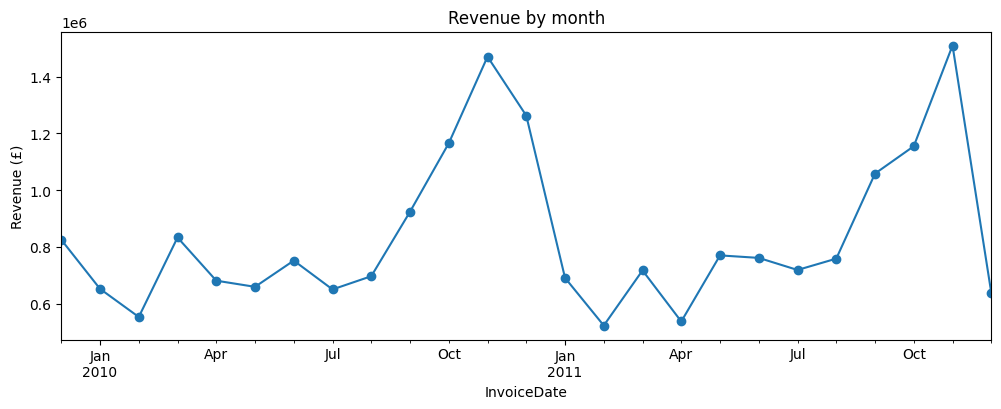

In [34]:
sales = df_raw[(df_raw['Quantity'] > 0) & (df_raw['Price'] > 0)].copy()
sales['Revenue'] = sales['Quantity'] * sales['Price']

monthly = sales.groupby(sales['InvoiceDate'].dt.to_period('M'))['Revenue'].sum()

monthly.plot(figsize=(12, 4), marker='o', title='Revenue by month')
plt.ylabel('Revenue (£)')
plt.show()

**Finding:** revenue peaks every **November** and is lowest in February. Customers buy gifts before Christmas, so the business is highly seasonal.

**4.4 Revenue by country**

Number of countries: 43


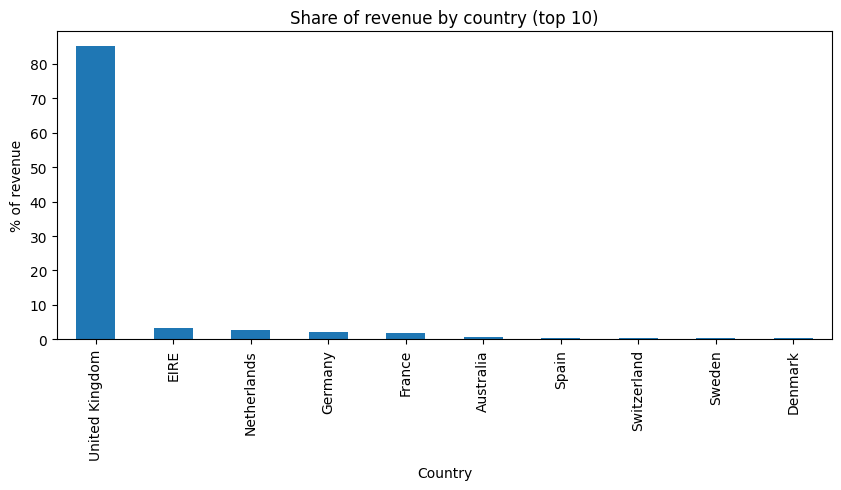

In [35]:
print('Number of countries:', df_raw['Country'].nunique())

country = sales.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
(country / country.sum() * 100).head(10).plot(kind='bar', figsize=(10, 4), title='Share of revenue by country (top 10)')
plt.ylabel('% of revenue')
plt.show()

**Finding:** customers come from 43 countries, but the **UK alone brings 85% of revenue** and about 91% of customers.

**4.5 Top 10 products**

In [36]:
sales.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

,Quantity
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,110138
WHITE HANGING HEART T-LIGHT HOLDER,96683
ASSORTED COLOUR BIRD ORNAMENT,81809
"PAPER CRAFT , LITTLE BIRDIE",80995
JUMBO BAG RED RETROSPOT,79279
MEDIUM CERAMIC TOP STORAGE JAR,78033
BROCADE RING PURSE,71430
PACK OF 60 PINK PAISLEY CAKE CASES,56794
60 TEATIME FAIRY CAKE CASES,54716


**Finding:** the best sellers are cheap gift and decoration items bought in very large quantities, which shows many customers are **wholesalers**. A few of them spend far more than everyone else.

---
# Part B – Như

## 5. Data Cleaning

## 6. Feature Engineering & Transformation

**6.1 Create 7 features for each customer**

| Feature | Meaning | Data type |
|---|---|---|
| Recency | Days since last purchase | Date/time |
| Frequency | Number of orders | Numeric |
| Monetary | Total money spent (£) | Numeric |
| AvgOrderValue | Money per order | Numeric |
| UniqueProducts | Number of different products bought | Numeric |
| Tenure | Days since first purchase | Date/time |
| IsUK | 1 = customer in the UK, 0 = other country | Categorical |

**6.2 Fix skewed data**

**6.3 Scale the data**

**6.4 (Optional) Download the CSV files**

In [47]:
# data_scaled.to_csv('customer_features.csv')
# customers.to_csv('customer_features_raw.csv')
# from google.colab import files
# files.download('customer_features.csv')
# files.download('customer_features_raw.csv')

---
# Part C – Ngọc

## 7. Model Development


### 7.1 K-Means


### 7.2 Hierarchical Clustering

### 7.3 Autoencoder + K-Means (Deep Learning)

## 8. Model Evaluation & Comparison

---
# Part D

## 9. Cluster Profiling & Business Recommendations

## 10. Tool Comparison: Python vs Orange vs Julius AI


## 11. Limitations & Future Work
